# Morphodynamic domain identification by spatially-constrained hierarchical clustering

<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); color: white; padding: 1.2em 1.8em; border-radius: 10px; margin-bottom: 1em;">

<p style="margin: 0 0 0.2em 0; font-weight: 300; font-size: 0.95em; letter-spacing: 0.05em; opacity: 0.85;">BELLAICHE LAB — Institut Curie</p>
<p style="margin: 0; font-size: 0.82em; opacity: 0.7;">Adrien Leroy, Eric van Leen, Maria Balakireva, Lale Alpar, Fabian Gärtner, Rémi Pigache, Isabelle Gaugué, Stéphane Pelletier, Mehdi Ech-Chouini, Julien Delpierre, Stéphane Rigaud, Floris Bosveld, Lorette Noiret, Yohanns Bellaïche</p>
<p style="margin: 0.1em 0 0 0; font-size: 0.75em; opacity: 0.5;">April 2026</p>

</div>

In [Leroy, van Leen et al., Cell Reports (2026)](https://doi.org/10.5281/zenodo.19633285) we introduce **morphodynamic domains** to integrate live-imaging morphometrics with spatial transcriptomics: spatiotemporal measurements on a gridded tissue are reduced with PCA, and the tissue is segmented by spatially-constrained agglomerative clustering.

Here we apply it to the *Drosophila* pupal notum, using 30 morphogenetic features from 8 averaged time-lapse movies (40 µm bins, two developmental windows). The same approach applies to any 2-D epithelium with quantitative morphometric data. The domains are combined with the spatial transcriptome of [notebook 02](02_spatial_transcriptome_reconstruction.ipynb) to infer gene regulatory networks ([notebook 03](03_grn_analysis.ipynb)), tested by phenotypic comparison in [notebook 04](04_morphodynamics_comparison.ipynb).

**Contents**

1. [Setup](#1.-Setup)
2. [The data](#2.-The-data)
3. [Tissue flow and deformation](#3.-Tissue-flow-and-deformation)
4. [From tensor fields to feature matrix](#4.-From-tensor-fields-to-feature-matrix)
5. [PCA](#5.-PCA)
6. [Spatially-constrained clustering](#6.-Spatially-constrained-clustering)
7. [Isolated-bin correction](#7.-Isolated-bin-correction)
8. [Feature visualisation](#8.-Feature-visualisation)



## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import zarr
from skimage.measure import label as skimage_label

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import radius_neighbors_graph
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from pyanimalprocessing.plotting import read_property, plot_property
from pyanimalprocessing.plotting.napari_plotting import add_tensor_legends
from pyanimalprocessing.plotting.napari_export import save_viewer_state
import napari

from pyanimalprocessing.spatial_statistics import clean_clusters
from vgep.plotter import geometric

MORPHODOMAINS_ROOT = Path("..").resolve()
sys.path.insert(0, str(MORPHODOMAINS_ROOT))
from scripts.build_morpho_clustering import build as build_morpho_clustering
from scripts.figures.figure_morphodynamic_domains._helpers import create_cluster_heatmap
from scripts.figures.figure_morphodynamic_domains.preprocessing import COLORS_5, COLUMNS_RENAMING
from scripts.figures.figure_morphodynamic_domains.panels_heatmaps import CELL_WIDTH_5

## 2. The data

All quantities come from the MATLAB SAP/MAP pipeline, converted to zarr with [`zarrify_SAP` / `zarrify_MAP`](https://github.com/BellaicheLab/AnimalProcessing). We use three stores:

- **`210507_vi_pupa1`** — a reference *vRNAi* (control) animal: raw images, tissue outlines and cell tracking.
- **`241002_eulerian`** — Eulerian averages over 8 *vRNAi* animals: `UPIV` (velocity) and `EpsilonPIV` (deformation rate), measured by PIV without tracking cells.
- **`240920_lagrangian`** — Lagrangian averages over the same animals: the decomposition of tissue deformation into cell growth (`EG`), division (`ED`), apoptosis (`EA`), rearrangement (`ER`) and shape change (`ES`), plus scalar fields.

To average animals, each movie is rescaled onto a common 40 µm grid and developmental timeline. On the **Eulerian** grid each bin stays fixed in the lab frame; on the **Lagrangian** grid it follows the tissue through cell tracking, which the decomposition requires. We use the **4 h window with 98 % overlap**. Spatial axes are `(y, x)` throughout, and vectors are stored as `(dy, dx)`.

### Reference animal (the parts used here)

```
/
├── IMAGE/D2/raw, outlines, mask          (T, [1,] y, x)  images
├── TRACKING/masks_division_agnostic      (T, y, x)       tracked cell labels
└── TIME_AVERAGE/<grid>/D2/<backup>/      per-animal time averages
```

### Averaged stores

```
/LAGRANGIAN_TRACKING/D2/                  (EULERIAN/D2/ for the Eulerian store)
├── AOA_avgAnimals_vi_0h_0olap/           instantaneous
├── AOA_avgAnimals_vi_4h_0.98olap/        4 h window  ★ used here
│   ├── EG, ED, EA, ER, ES, Epsilon       (T, 1, ny, nx, 4, N+1)  2×2 tensors
│   ├── U                                 (T, 1, ny, nx, 2, N+1)  velocity
│   ├── CellArea, dnD, dnA, …             (T, 1, ny, nx, 1, N+1)  scalars
│   └── AreaRatios                        coverage fraction (quality mask)
└── …                                     2 h and 6 h windows
```

The last axis holds the `N` animals (8 *vRNAi*, 5 *TolloRNAi*) after index 0, the cross-animal mean.

In [2]:
# Default: the Zenodo archive root (contains data/), two levels above notebooks/.
# Override with MORPHODOMAINS_DATA.
DATA_ROOT = Path(os.environ.get(
    "MORPHODOMAINS_DATA",
    str(Path("..").resolve().parents[1]),
))

ZARR_ANIMAL    = DATA_ROOT / "data/zarr/210507_vi_pupa1.zarr"
ZARR_EULERIAN  = DATA_ROOT / "data/zarr/averages_v3/241002_eulerian"
ZARR_LAGRANGIAN = DATA_ROOT / "data/zarr/averages_v3/240920_lagrangian"

animal         = zarr.open_group(str(ZARR_ANIMAL), "r")
avg_eulerian   = zarr.open(str(ZARR_EULERIAN), mode="r")
avg_lagrangian = zarr.open(str(ZARR_LAGRANGIAN), mode="r")

NOTEBOOK_OUTPUTS = Path("notebook_outputs") / "morphodynamic_domains"
NOTEBOOK_OUTPUTS.mkdir(parents=True, exist_ok=True)

# Eulerian backup (PIV-based, no cell tracking).  The averaged zarrs nest the
# backups under <MOTION>/D2/; the animal store itself provides the SAP
# registration used by read_property (reference_animal=animal).
AOA_eul_4h = avg_eulerian["EULERIAN"]["D2"]["AOA_avgAnimals_vi_4h_0.98olap"]

# Lagrangian backup (cell-tracked decomposition)
AOA_lag_4h = avg_lagrangian["LAGRANGIAN_TRACKING"]["D2"]["AOA_avgAnimals_vi_4h_0.98olap"]
tracking_mask = np.array(animal["TRACKING"]["masks_division_agnostic"])

print(f"Eulerian zarr:  {ZARR_EULERIAN.name}")
print(f"Lagrangian zarr: {ZARR_LAGRANGIAN.name}")
print(f"Reference animal: {ZARR_ANIMAL.name}")
print(f"Tracking mask: {tracking_mask.shape}")


Eulerian zarr:  241002_eulerian
Lagrangian zarr: 240920_lagrangian
Reference animal: 210507_vi_pupa1.zarr
Tracking mask: (236, 2079, 3763)


## 3. Tissue flow and deformation

We show the Eulerian fields (velocity, deformation rate), then the Lagrangian decomposition into cellular processes.

### Eulerian: velocity and total deformation rate

`read_property` reads a quantity from a backup, applies the coverage and significance filters, and returns a bundle ready to render; `reference_animal=` overlays the averaged grid onto that movie. `plot_property` adds the bundle to a napari viewer, `add_tensor_legends` adds the quantity and time legends, and `save_viewer_state` exports the view.

In [3]:
# Clean tissue outlines: remove the largest connected component (background)
# and replace NaN (outside-tissue) with white (1.0) for the viewer
raw_outline = np.array(animal.IMAGE.D2.outlines).astype(float)
clean_outline = np.empty_like(raw_outline)
clean_outline[:] = np.nan
for i in range(raw_outline.shape[0]):
    tmp = skimage_label(raw_outline[i], connectivity=1)
    mask = tmp != 1
    clean_outline[i][mask] = raw_outline[i][mask]
np.nan_to_num(clean_outline, copy=False, nan=1.0)

raw_image = np.array(animal.IMAGE.D2.raw)[:, 0].astype(float)  # drop the channel axis

In [4]:
# The averaged pattern is overlaid onto the movie via its SAP registration
# (reference_animal supplies the affine; origins are the archetype grid).
# Outliers are clipped (2/98 percentile) at render time by plot_property.
velocity_fields = read_property(
    AOA_eul_4h, "UPIV", reference_animal=animal,
    grid_bulk_threshold=0.55, significance=0,
)

deformation_fields = read_property(
    AOA_eul_4h, "EpsilonPIV", reference_animal=animal,
    grid_bulk_threshold=0.55, significance=0,
)


In [5]:
viewer = napari.Viewer()
viewer.theme = "light"
viewer.add_image(clean_outline, name="outline")
viewer.add_image(raw_image, name="raw", colormap="gray_r", contrast_limits=(97, 160))

<Image layer 'raw' at 0x7fe531411c00>

In [6]:
plot_property(
    **{**velocity_fields, "property_name": "Velocity"},
    viewer=viewer,
    vector_scale=20,
    rescale_property="Rotation",
    clipping_percentile=(0.02, 0.98),
    vectors_kwargs={
        "edge_color": "#FF732E",
        "vector_style": "triangle",
        "edge_width": 15,
        "opacity": 1,
    },
)

add_tensor_legends(
    viewer,
    time_array=AOA_eul_4h.attrs["TimeArray"],
    image_size=(2079, 3763),
    quantity="Velocity",
    start_frame=int(round(np.asarray(velocity_fields["affine_transform"])[0, -1])),
    quantity_color="#FF732E",
    quantity_anchor="lower_left", quantity_translation=[-250, 50],
    time_color="black",
    time_anchor="lower_left", time_translation=[-130, 50],
    legend_size=30,
)

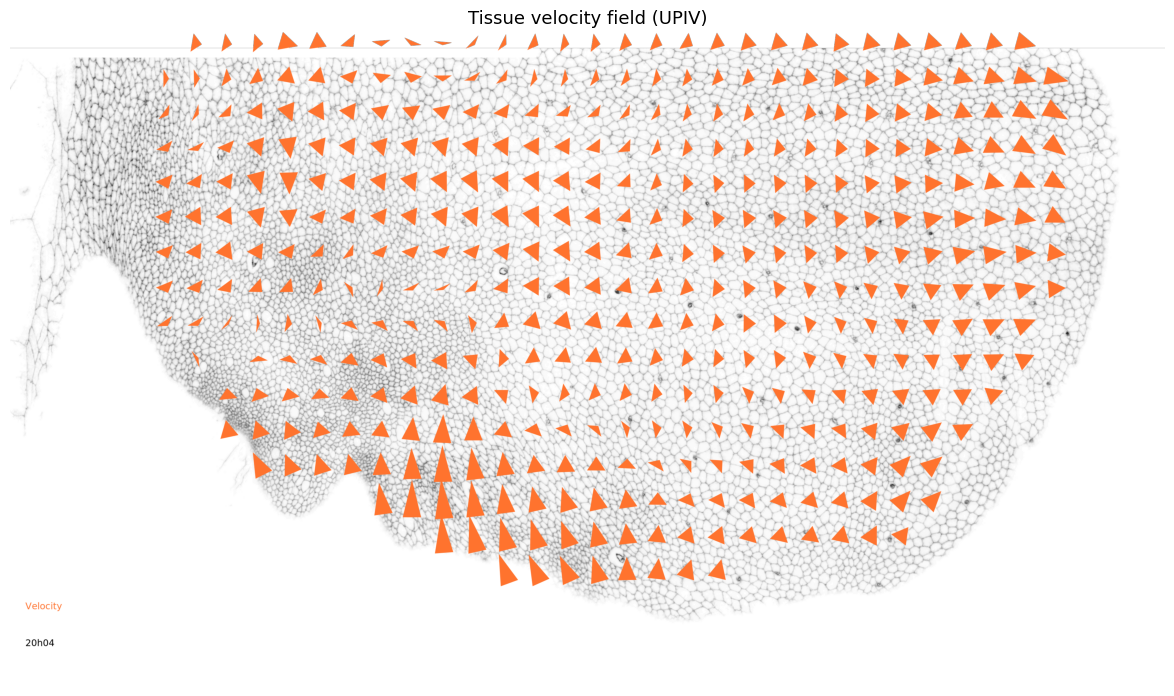

In [7]:
save_viewer_state(viewer, str(NOTEBOOK_OUTPUTS / "velocity.png"), frames=94,
    layers=[
        "raw",
        "Velocity",
        "quantity legend",
        "median time legend",
    ])

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(plt.imread(NOTEBOOK_OUTPUTS / "velocity.png"))
ax.set_axis_off()
ax.set_title("Tissue velocity field (UPIV)", fontsize=13)
plt.tight_layout()
plt.show()


In [8]:
viewer.layers.clear()
viewer.add_image(clean_outline, name="outline")
viewer.add_image(raw_image, name="raw", colormap="gray_r", contrast_limits=(97, 160))

plot_property(
    **{**deformation_fields, "property_name": "Deformation rate"},
    viewer=viewer,
    vector_scale=3000,
    scalar_scale=3000,
    rescale_property="Rotation",
    clipping_percentile=(0.02, 0.98),
    vectors_kwargs={
        "edge_color": "blue",
        "vector_style": "line",
        "edge_width": 8,
        "opacity": 1,
    },
)

add_tensor_legends(
    viewer,
    time_array=AOA_eul_4h.attrs["TimeArray"],
    image_size=(2079, 3763),
    quantity="Deformation rate",
    start_frame=int(round(np.asarray(deformation_fields["affine_transform"])[0, -1])),
    quantity_color="blue",
    quantity_anchor="lower_left", quantity_translation=[-250, 50],
    time_color="black",
    time_anchor="lower_left", time_translation=[-130, 50],
    legend_size=30,
)

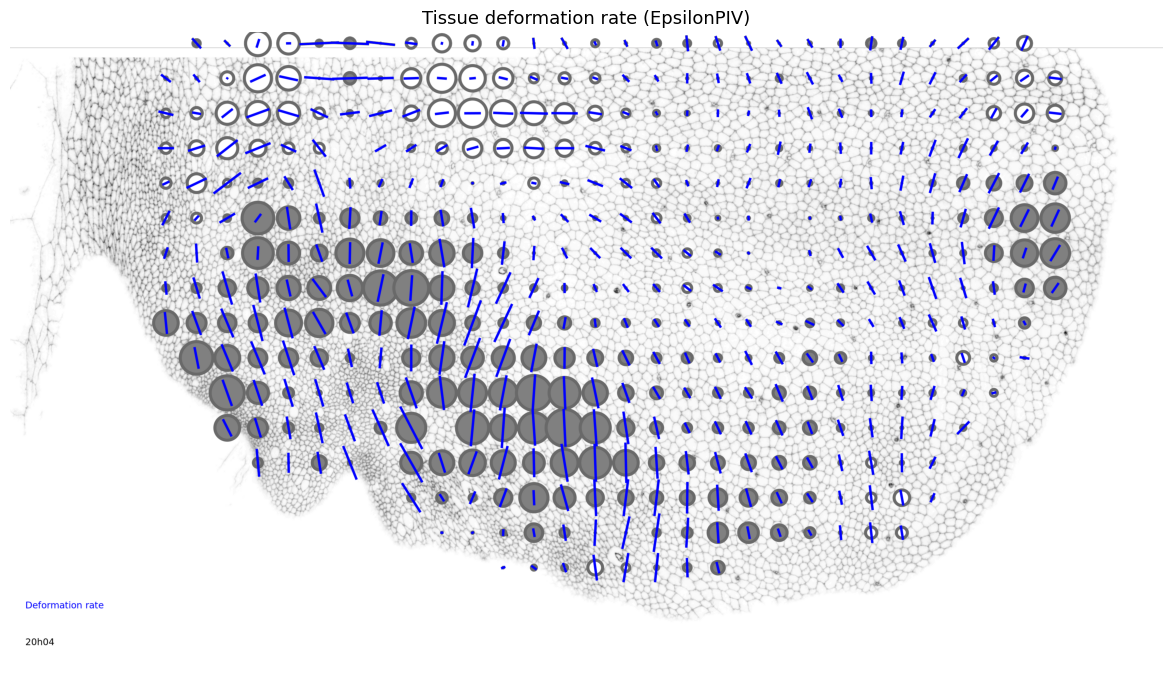

In [9]:
save_viewer_state(viewer, str(NOTEBOOK_OUTPUTS / "deformation.png"), frames=94,
    layers=[
        "raw",
        "positive_Deformation rate (shapes)",
        "negative_Deformation rate (shapes)",
        "Deformation rate_positive",
        "quantity legend",
        "median time legend",
    ])

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(plt.imread(NOTEBOOK_OUTPUTS / "deformation.png"))
ax.set_axis_off()
ax.set_title("Tissue deformation rate (EpsilonPIV)", fontsize=13)
plt.tight_layout()
plt.show()


### Lagrangian: cellular contributions to deformation

The decomposition follows material points through time, using the division-agnostic tracking in `TRACKING/masks_division_agnostic` (daughter cells merged back with their mother). `read_property(..., lagrangian=True, tracking_mask=...)` computes the fields in that frame. We show rearrangement (ER), division (ED), apoptosis (EA) and shape change (ES).

In [10]:
lagrangian_quantities = {
    "ER": {"scale": 1500, "color": "#99288c", "name": "Rearrangement (R)", "style": "line"},
    "ED": {"scale": 750,  "color": "#14812a", "name": "Division (D)",      "style": "line"},
    "EA": {"scale": 3000, "color": "#474545", "name": "Apoptosis (A)",     "style": "line"},
    "ES": {"scale": 750,  "color": "#12d0fb", "name": "Shape change (S)",  "style": "line"},
}

# Scalar values and vector magnitudes are clamped at the 2/98 percentile at
# render time (plot_property's clipping_percentile) to suppress outliers that
# would otherwise distort circle sizes and vector lengths.
lagrangian_fields = {}
for qty, cfg in lagrangian_quantities.items():
    lagrangian_fields[qty] = read_property(
        AOA_lag_4h, qty, reference_animal=animal,
        grid_bulk_threshold=0.15, significance=0,
        lagrangian=True, tracking_mask=tracking_mask, lagrangian_time_ref="17h40",
    )


`save_viewer_state` converts point markers to shapes before exporting, so they keep their true size at any zoom; hence the `(shapes)` layer names below.

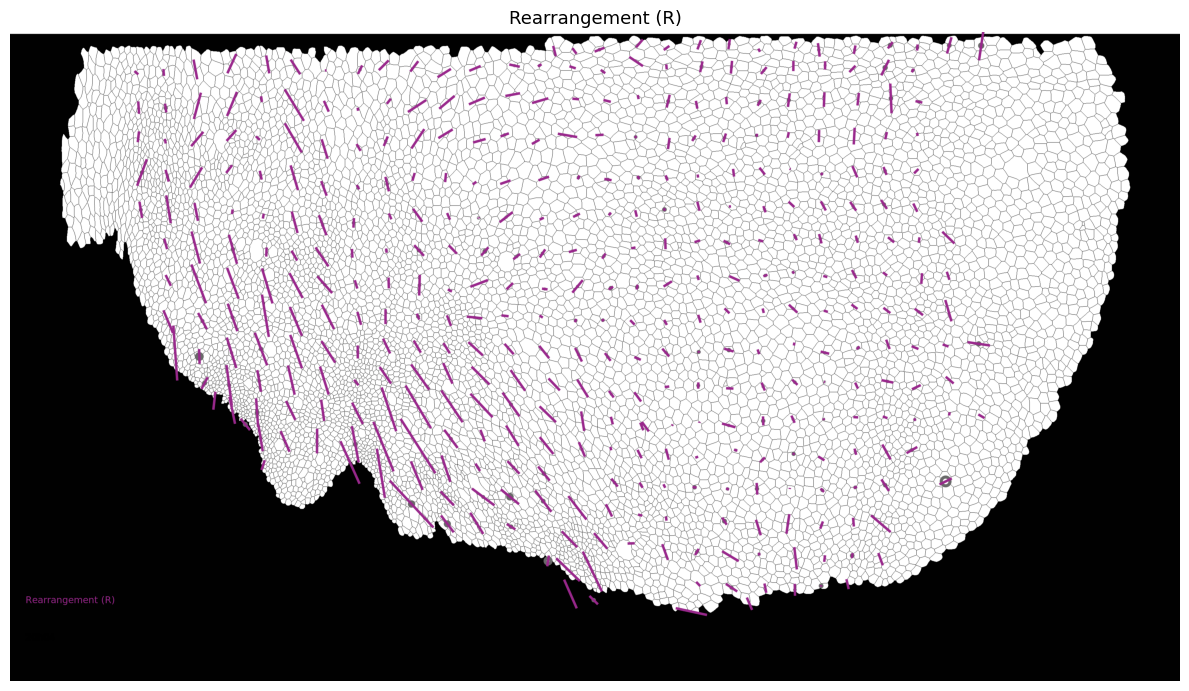

Layer selection: 1 layer(s) not found in viewer: ['negative_Division (D) (shapes)']. Available layers: ['Division (D)_negative', 'Division (D)_positive', 'median time legend', 'outline', 'positive_Division (D) (shapes)', 'quantity legend', 'time legend']


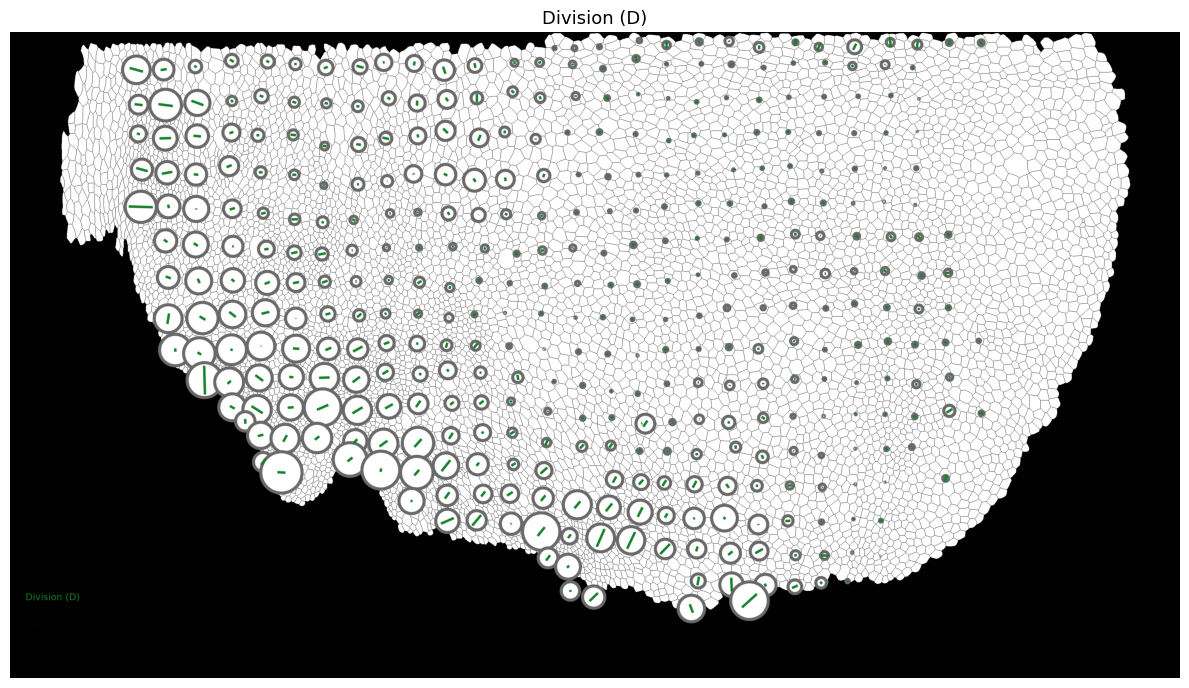

Layer selection: 1 layer(s) not found in viewer: ['positive_Apoptosis (A) (shapes)']. Available layers: ['Apoptosis (A)_negative', 'Apoptosis (A)_positive', 'median time legend', 'negative_Apoptosis (A) (shapes)', 'outline', 'quantity legend', 'time legend']


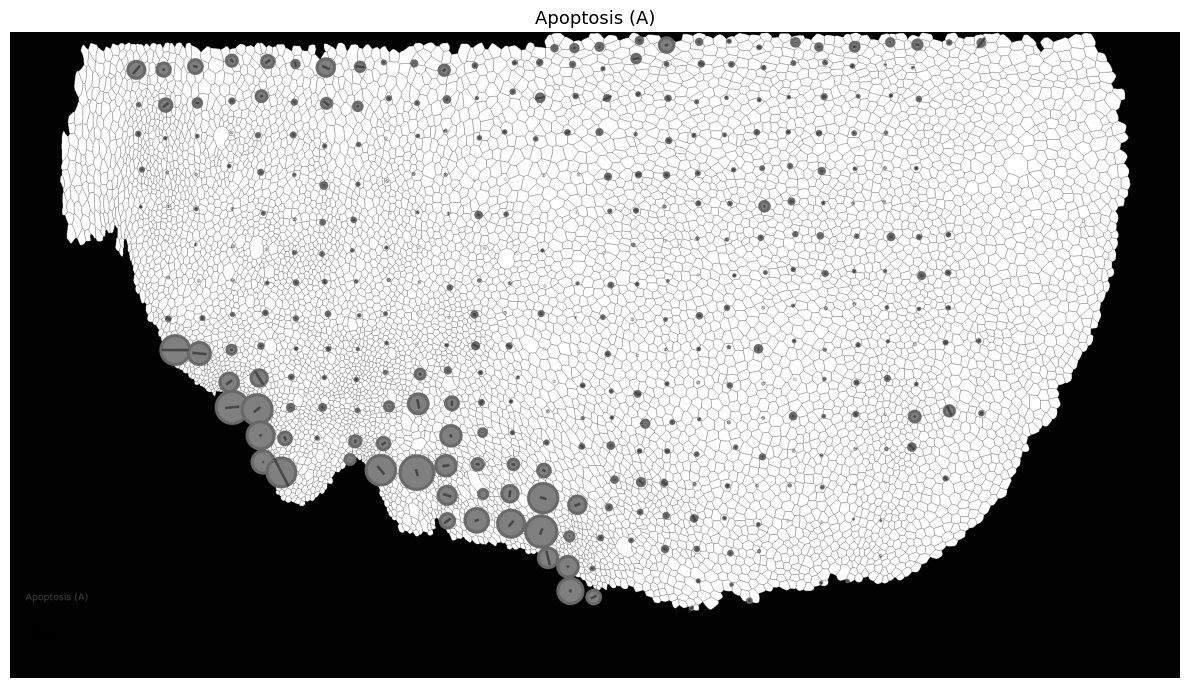

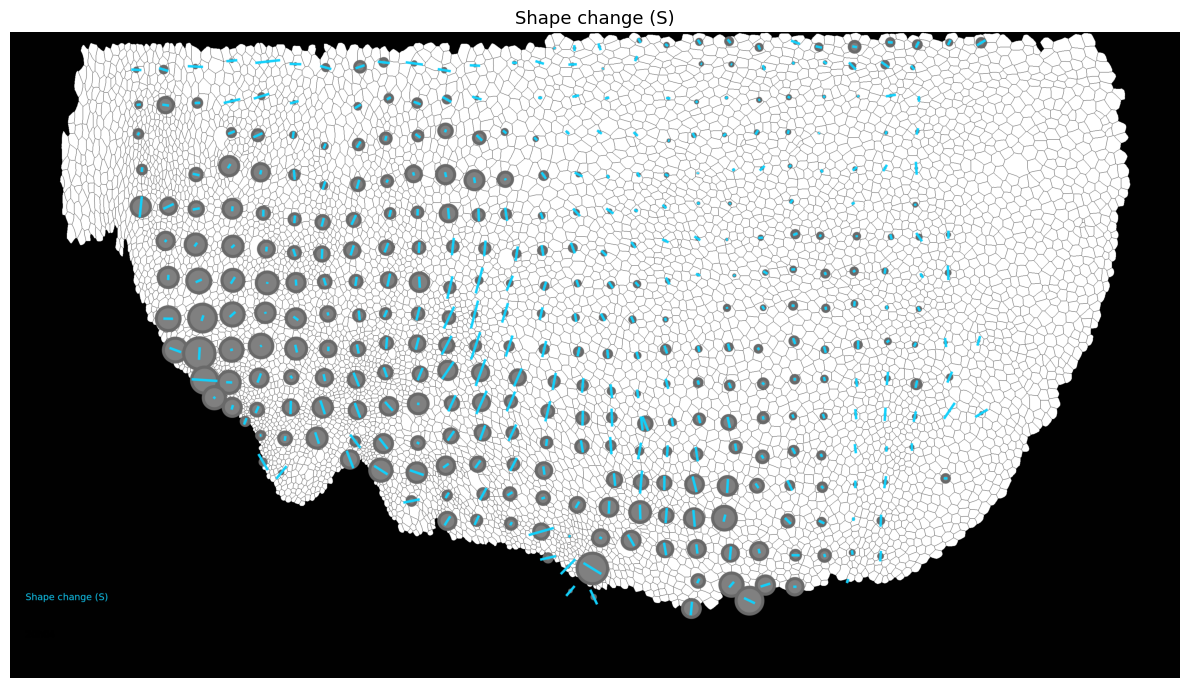

In [11]:
LAGRANGIAN_LAYERS = {
    "ER": [
        "outline",
        "positive_Rearrangement (R) (shapes)",
        "Rearrangement (R)_positive",
        "quantity legend",
        "median time legend",
    ],
    "ED": [
        "outline",
        "positive_Division (D) (shapes)",
        "negative_Division (D) (shapes)",
        "Division (D)_positive",
        "quantity legend",
        "median time legend",
    ],
    "EA": [
        "outline",
        "positive_Apoptosis (A) (shapes)",
        "negative_Apoptosis (A) (shapes)",
        "Apoptosis (A)_positive",
        "quantity legend",
        "median time legend",
    ],
    "ES": [
        "outline",
        "positive_Shape change (S) (shapes)",
        "negative_Shape change (S) (shapes)",
        "Shape change (S)_positive",
        "quantity legend",
        "median time legend",
    ],
}


# Vectors are scaled separately from values (figure_morphodynamic_domains convention: ×2 vectors
# only, leaving the eigenvalue circles at their natural magnitude).
VECTOR_SCALE_FACTOR = 2.0

for qty, cfg in lagrangian_quantities.items():
    viewer.layers.clear()
    viewer.add_image(clean_outline, name="outline")

    bundle = lagrangian_fields[qty]
    start_frame = int(round(np.asarray(bundle["affine_transform"])[0, -1]))

    plot_property(
        **{**bundle, "property_name": cfg["name"]},
        viewer=viewer,
        vector_scale=cfg["scale"] * VECTOR_SCALE_FACTOR,
        scalar_scale=cfg["scale"],
        rescale_property="Rotation",
        clipping_percentile=(0.02, 0.98),
        vectors_kwargs={
            "edge_color": cfg["color"],
            "vector_style": cfg["style"],
            "edge_width": 8,
            "opacity": 1,
        },
    )

    add_tensor_legends(
        viewer,
        time_array=AOA_lag_4h.attrs["TimeArray"],
        image_size=(2079, 3763),
        quantity=cfg["name"],
        start_frame=start_frame,
        quantity_color=cfg["color"],
        quantity_anchor="lower_left", quantity_translation=[-250, 50],
        time_color="black",
        time_anchor="lower_left", time_translation=[-130, 50],
        legend_size=30,
    )

    out_path = str(NOTEBOOK_OUTPUTS / f"{qty}.png")
    save_viewer_state(viewer, out_path, frames=94, layers=LAGRANGIAN_LAYERS[qty])

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(plt.imread(out_path))
    ax.set_axis_off()
    ax.set_title(cfg["name"], fontsize=13)
    plt.tight_layout()
    plt.show()

viewer.close()



## 4. From tensor fields to feature matrix

For clustering, condense the spatiotemporal tensor fields in two time windows — *early* (18–22 hAPF) and *late* (22–26 hAPF).

**Per time window, 15 quantities are extracted:**

- *5 isotropic rates* — the trace (λ₁ + λ₂) of each decomposition tensor (EG, ED, EA, ER, ES), capturing how much each cellular process contributes to tissue dilation.
- *5 deviatoric rates* — the eigenvalue difference (λ₁ − λ₂)/2 of the same tensors, capturing the contribution to tissue convergent extension.
- *Velocity magnitude* — ‖U‖, the norm of the PIV velocity vector.
- *Cell anisotropy* — elongation of cell shapes.
- *Normalised division and apoptosis rates* — division and apoptosis event counts normalised by the number of cells at the start of the window.
- *Cell area* — mean apical area of cells in the bin.

Three filtering steps then clean the data: bins with low area-ratio coverage (< 0.15) are masked, spatially isolated pixels are removed iteratively, and apoptosis-rate outliers are dropped. The implementation is in `scripts/build_morpho_clustering.py`.


In [12]:
Mrph = build_morpho_clustering(str(ZARR_LAGRANGIAN))
Mrph = Mrph.rename(columns=COLUMNS_RENAMING)
Mrph = Mrph[[c for c in COLUMNS_RENAMING.values() if c in Mrph.columns]]

print(f"Feature matrix: {Mrph.shape[0]} spatial bins × {Mrph.shape[1]} features")
print(f"Index: {Mrph.index.names}")
Mrph.head()

Feature matrix: 389 spatial bins × 30 features
Index: ['x', 'y']


G → dilation (early)  D → dilation (early)  A → dilation (early)  \
x y                                                                      
4 22              0.019240              0.105337             -0.036654   
  23              0.018941              0.084184             -0.057230   
  24              0.044187              0.075009             -0.028193   
  25              0.076225              0.127458             -0.013651   
  26              0.051132              0.096145             -0.027872   

      R → dilation (early)  S → dilation (early)  G → elongation (early)  \
x y                                                                        
4 22              0.005069             -0.039060               -0.071192   
  23             -0.013016              0.022623               -0.055010   
  24             -0.009911              0.007746               -0.031317   
  25             -0.011168             -0.019647               -0.008384   
  26             -0.003702             -0.007743               -0.006879   

      D → elongation (early)  A → elongation (early)  R → elongation (early)  \
x y                                                                            
4 22               -0.014233               -0.007336               -0.007126   
  23               -0.010917               -0.007860               -0.013045   
  24               -0.004101               -0.004227               -0.011600   
  25               -0.008054               -0.001892               -0.014798   
  26               -0.007737               -0.003872               -0.017121   

      S → elongation (early)  ...  G → elongation (late)  \
x y                           ...                          
4 22               -0.061974  ...              -0.023749   
  23               -0.059974  ...              -0.009441   
  24               -0.026977  ...              -0.014329   
  25               -0.024690  ...              -0.009748   
  26               -0.015930  ...              -0.027651   

      D → elongation (late)  A → elongation (late)  R → elongation (late)  \
x y                                                                         
4 22              -0.000345              -0.006508              -0.038187   
  23              -0.021839              -0.006137              -0.015972   
  24              -0.007317              -0.001861              -0.013593   
  25              -0.004466              -0.003516              -0.037668   
  26              -0.006470              -0.005523              -0.051758   

      S → elongation (late)  Velocity (late)  Anisotropy (late)  \
x y                                                               
4 22              -0.025639         5.216243           0.298746   
  23              -0.020789         4.811654           0.262195   
  24              -0.004229         4.577298           0.190650   
  25              -0.045549         3.935544           0.155171   
  26              -0.031956         3.986144           0.101374   

      Normalized division rate (late)  Normalized apoptosis rate (late)  \
x y                                                                       
4 22                         0.108176                          0.084257   
  23                         0.116563                          0.084743   
  24                         0.126150                          0.105494   
  25                         0.046786                          0.056847   
  26                         0.029860                          0.028466   

      Cellular area (late)  
x y                         
4 22             19.882977  
  23             18.617380  
  24             21.309713  
  25             23.445171  
  26             26.654356  

[5 rows x 30 columns]

In [13]:
x_vals = Mrph.index.get_level_values("x").astype(int)
y_vals = Mrph.index.get_level_values("y").astype(int)
X_MAX, Y_MAX = x_vals.max() + 1, y_vals.max() + 1

def bins_to_image(series):
    """Convert a bin-indexed Series to a 2-D numpy array for imshow."""
    img = np.full((X_MAX, Y_MAX), np.nan)
    for (x, y), v in series.items():
        img[int(x), int(y)] = v
    return img

print(f"Grid size: {X_MAX} × {Y_MAX}")

Grid size: 22 × 43


## 5. PCA

### 5.1 Standardisation and fit

In [14]:
scaler = StandardScaler()
Mrph_sc_values = scaler.fit_transform(Mrph)
Mrph_sc = pd.DataFrame(Mrph_sc_values, index=Mrph.index, columns=Mrph.columns)

pca = PCA()
scores_all = pca.fit_transform(Mrph_sc)
Mrph_PCA = pd.DataFrame(
    scores_all, index=Mrph_sc.index,
    columns=[f"PC{i+1}" for i in range(scores_all.shape[1])],
)

print(f"PCA fitted on {Mrph_sc.shape[0]} bins × {Mrph_sc.shape[1]} features")
print(f"PC1 explains {pca.explained_variance_ratio_[0]*100:.1f}% of variance")
print(f"PC2 explains {pca.explained_variance_ratio_[1]*100:.1f}% of variance")

PCA fitted on 389 bins × 30 features
PC1 explains 32.9% of variance
PC2 explains 9.6% of variance


### 5.2 Explained variance

Components needed to explain ≥ 90 % variance: 14


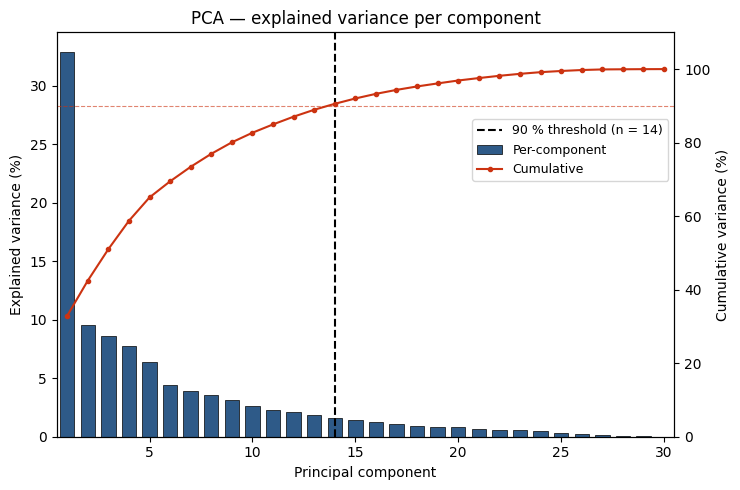

In [15]:
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components_90 = int(np.argmax(cumvar >= 0.90)) + 1
print(f"Components needed to explain ≥ 90 % variance: {n_components_90}")

fig, ax = plt.subplots(figsize=(7.5, 5))
x = range(1, len(pca.explained_variance_ratio_) + 1)
ax.bar(x, pca.explained_variance_ratio_ * 100, color="#2E5A88", width=0.7, edgecolor="black", linewidth=0.5, label="Per-component")
ax2 = ax.twinx()
ax2.plot(x, cumvar * 100, "o-", color="#CC3311", markersize=3, label="Cumulative")
ax2.axhline(90, color="#CC3311", linestyle="--", linewidth=0.8, alpha=0.6)
ax.axvline(n_components_90, color="black", linestyle="--", linewidth=1.5, label=f"90 % threshold (n = {n_components_90})")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance (%)")
ax2.set_ylabel("Cumulative variance (%)"); ax2.set_ylim(0, 110)
ax.set_xlim(0.5, len(x) + 0.5)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc="upper right", bbox_to_anchor=(1.0, 0.8))
ax.set_title("PCA — explained variance per component", fontsize=12)
plt.tight_layout(); plt.show()

### 5.3 Loadings — PC1 and PC2

Loadings indicate how much each original feature contributes to a principal component.

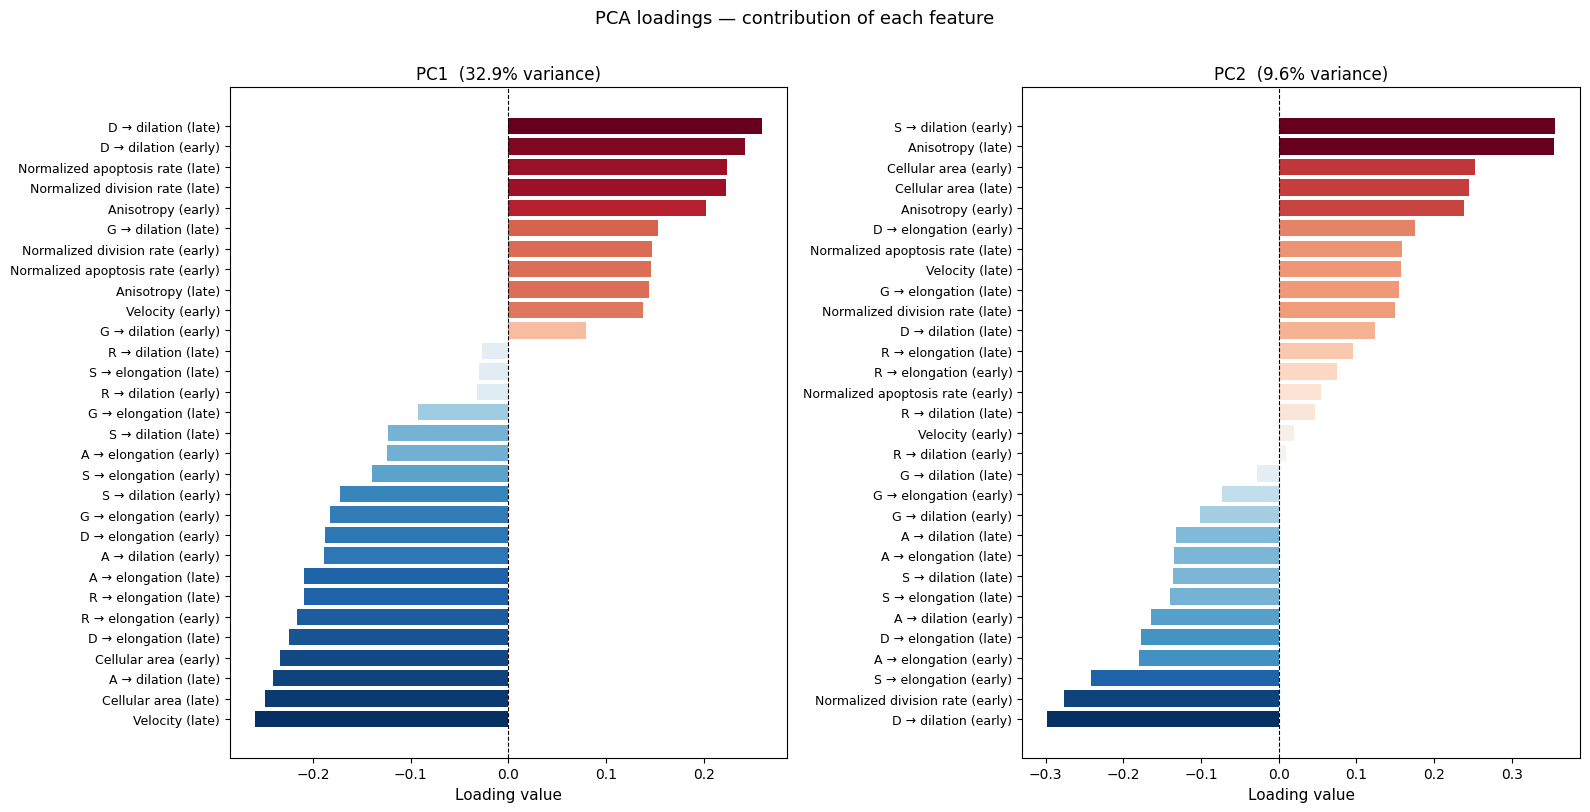

In [16]:
loadings = pd.DataFrame(pca.components_.T, index=Mrph_sc.columns, columns=[f"PC{i+1}" for i in range(pca.n_components_)])
cmap_loading = plt.cm.RdBu_r

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=False)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    vals = loadings[pc].sort_values(ascending=True)
    norm = TwoSlopeNorm(vmin=vals.min(), vcenter=0, vmax=vals.max())
    colors = cmap_loading(norm(vals.values))
    ax.barh(range(len(vals)), vals.values, color=colors)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(vals.index, fontsize=9)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Loading value", fontsize=11)
    ax.set_title(f"{pc}  ({pca.explained_variance_ratio_[int(pc[2:])-1]*100:.1f}% variance)", fontsize=12)
plt.suptitle("PCA loadings — contribution of each feature", fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

### 5.4 Spatial maps of PC1 and PC2

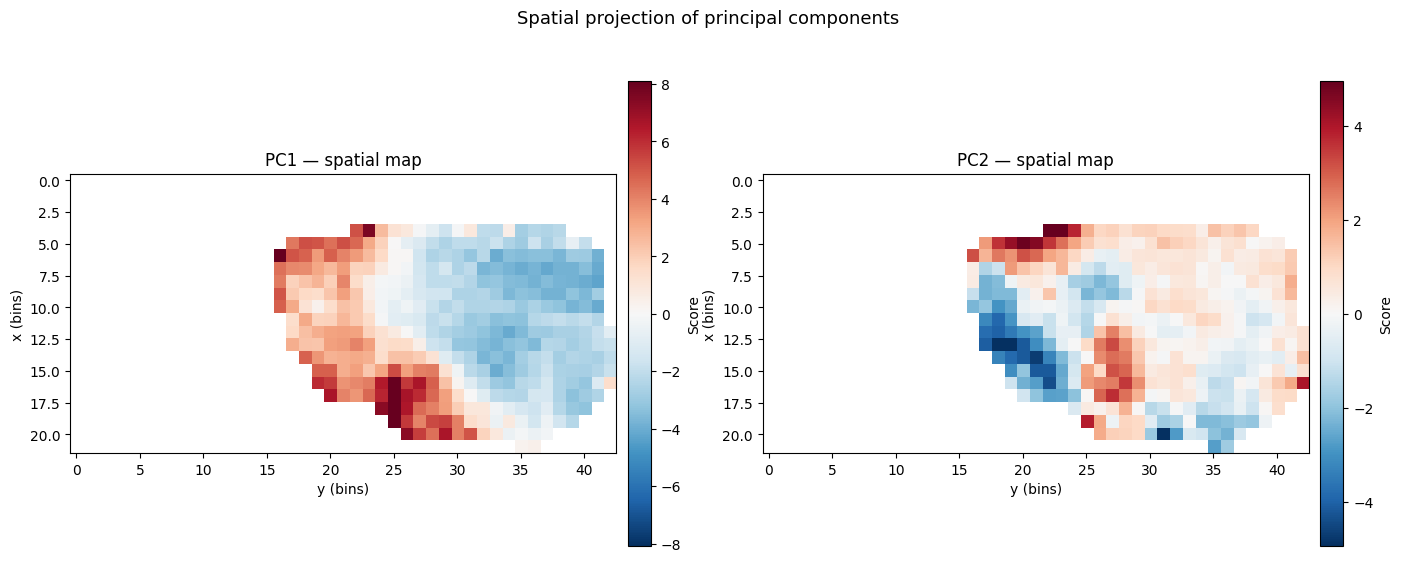

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pc, title in zip(axes, ["PC1", "PC2"], ["PC1 — spatial map", "PC2 — spatial map"]):
    img = bins_to_image(Mrph_PCA[pc])
    vmax = np.nanpercentile(np.abs(img), 99)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    im = ax.imshow(img, cmap="RdBu_r", norm=norm, origin="upper", aspect="equal")
    plt.colorbar(im, ax=ax, label="Score", fraction=0.04, pad=0.02)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("y (bins)"); ax.set_ylabel("x (bins)")
plt.suptitle("Spatial projection of principal components", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Spatially-constrained clustering

### 6.1 Connectivity graph

A radius-neighbour graph enforces spatial contiguity: two bins can only be merged if they are adjacent (including diagonals). The radius is set to √2 in bin units so that the 8-connected neighbourhood is included.

Standard agglomerative clustering can produce fragmented domains. The connectivity graph ensures that all resulting domains are spatially contiguous.

In [18]:
coords = Mrph_sc.reset_index()[["x", "y"]].values
coords_transformed = np.column_stack([-coords[:, 0], coords[:, 1]])

connectivity_matrix = radius_neighbors_graph(
    coords_transformed, radius=np.sqrt(2), mode="connectivity", include_self=False,
)
n_edges = connectivity_matrix.nnz // 2
print(f"Connectivity graph: {coords.shape[0]} nodes, {n_edges} edges")
print(f"Mean degree: {n_edges * 2 / coords.shape[0]:.1f}")

Connectivity graph: 389 nodes, 1441 edges
Mean degree: 7.4


In [19]:
data_pca_reduced = scores_all[:, :n_components_90]
print(f"Clustering input: {data_pca_reduced.shape[0]} bins × {n_components_90} PCs (≥ 90 % variance)")

Clustering input: 389 bins × 14 PCs (≥ 90 % variance)


### 6.2 Clustering sweep (k = 2–13)

We compute the silhouette score for each partition from 2 to 13 domains. The score measures how well each bin fits its assigned domain compared to neighbouring domains; values range from −1 (mis-assigned) to +1 (well-separated).

In [20]:
N_RANGE = range(2, 14)
all_clusters = pd.DataFrame(index=Mrph_sc.index)
silhouette_scores = []

print("Running clustering sweep …")
for k in N_RANGE:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward", connectivity=connectivity_matrix)
    labels = model.fit_predict(data_pca_reduced)
    all_clusters[k] = labels
    score = silhouette_score(data_pca_reduced, labels)
    silhouette_scores.append(score)
    print(f"  k = {k:2d}  silhouette = {score:.4f}")

optimal_k = list(N_RANGE)[int(np.argmax(silhouette_scores))]
max_score = max(silhouette_scores)
print(f"\nOptimal number of domains: {optimal_k}  (score = {max_score:.4f})")

Running clustering sweep …
  k =  2  silhouette = 0.2874
  k =  3  silhouette = 0.2755
  k =  4  silhouette = 0.2847
  k =  5  silhouette = 0.2931
  k =  6  silhouette = 0.2358
  k =  7  silhouette = 0.2402
  k =  8  silhouette = 0.2469
  k =  9  silhouette = 0.2516
  k = 10  silhouette = 0.1723


  k = 11  silhouette = 0.1780


  k = 12  silhouette = 0.1801


  k = 13  silhouette = 0.1579

Optimal number of domains: 5  (score = 0.2931)


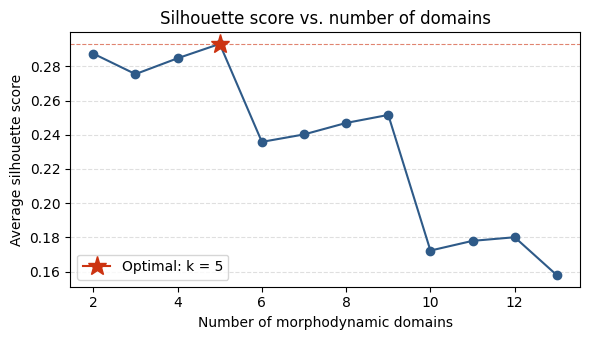

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(N_RANGE), silhouette_scores, marker="o", color="#2E5A88", linewidth=1.5)
ax.plot(optimal_k, max_score, marker="*", markersize=14, color="#CC3311", zorder=5, label=f"Optimal: k = {optimal_k}")
ax.axhline(max_score, color="#CC3311", linestyle="--", linewidth=0.8, alpha=0.6)
ax.set_xlabel("Number of morphodynamic domains"); ax.set_ylabel("Average silhouette score")
ax.set_title("Silhouette score vs. number of domains", fontsize=12)
ax.legend(fontsize=10); ax.yaxis.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

## 7. Isolated-bin correction

A bin whose four neighbours all carry other labels is *isolated*. `clean_clusters` (in `pyanimalprocessing.spatial_statistics`) gives it the most frequent neighbouring label (4-connected, then 8-connected on a tie), repeating until none remain, and re-indexes the labels.

In [22]:
all_clusters_clean = clean_clusters(all_clusters.copy())


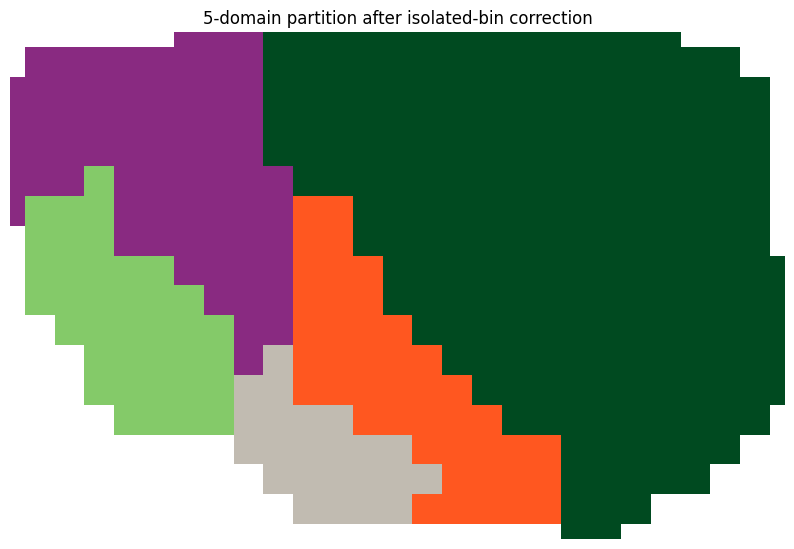

In [23]:
from matplotlib.colors import ListedColormap

labels_5 = all_clusters_clean[5]
cluster_df = pd.DataFrame({"domain": labels_5.values}, index=labels_5.index)


geometric(
    cluster_df,
    color="domain",
    title="5-domain partition after isolated-bin correction",
    colorbar=False,
    cmap=ListedColormap(COLORS_5),
)

## 8. Feature visualisation

### Z-score heatmap (5 domains)


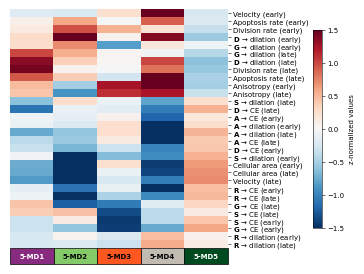

In [24]:
fig = create_cluster_heatmap(
    Mrph, all_clusters_clean[5],
    color_list=COLORS_5,
    column_labels=[f"5-MD{i}" for i in range(1, 6)],
    cell_width_pt=CELL_WIDTH_5,
)
plt.show()
